# Searching for Potentially Habitable Exoplanets with NASA Data

Out of thousands of planets discovered outside our solar system, which ones could support liquid water on their surface? This project uses real data from the [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/) to find planets that are the right size to be rocky and receive the right amount of energy from their star for liquid water, then uses machine learning to see how they fit into the wider population of known planets.

Uses pandas, NumPy, Matplotlib, and scikit-learn.

# 1. Import the libraries.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from urllib.parse import urlencode

# 2. Download the data

Build SQL query to get only the columns needed from the Planetary Systems Composite Parameters table ("pscompars"), turn the query into a URL, have pandas read the CSV straight from the NASA database, and save backup copy for all this data.

In [37]:
columns = [
    "pl_name",          # planet name
    "hostname",         # star name
    "discoverymethod",  # how it was found (transit, radial velocity, etc.)
    "disc_year",        # year discovered
    "pl_rade",          # planet radius (Earth radii)
    "pl_bmasse",        # planet mass (Earth masses)
    "pl_orbper",        # orbital period (days)
    "pl_orbsmax",       # orbital distance, semi-major axis (AU)
    "pl_insol",         # insolation flux (Earth = 1), NASA's own value
    "pl_eqt",           # equilibrium temperature (Kelvin)
    "st_teff",          # star surface temperature (Kelvin)
    "st_rad",           # star radius (Sun radii)
    "st_mass",          # star mass (Sun masses)
    "st_lum",           # star luminosity, log10 of Sun's luminosity
    "sy_dist",          # distance from Earth (parsecs)
]

query = f"select {','.join(columns)} from pscomppars"
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?" + urlencode(
    {"query": query, "format": "csv"}
)

df = pd.read_csv(url)
print(f"Downloaded {len(df)} planets with {df.shape[1]} columns")

# backup copy
df.to_csv("exoplanets_raw.csv", index=False)

Downloaded 6451 planets with 15 columns


# 3. Examine data
Show what percentage of each column is empty to inform the data cleaning process.

In [38]:
display(df.head())
print()
df.info()
print()
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("Percent missing per column:")
print(missing)

,pl_name,hostname,discoverymethod,disc_year,pl_rade,pl_bmasse,pl_orbper,pl_orbsmax,pl_insol,pl_eqt,st_teff,st_rad,st_mass,st_lum,sy_dist
0,55 Cnc b,55 Cnc,Radial Velocity,1996,13.900,263.9785,14.651552,0.11800,45.6336,700.00,5198.0,0.980,1.015,-0.19695,12.5855
1,55 Cnc c,55 Cnc,Radial Velocity,2004,8.510,54.4738,44.393600,0.24700,10.4149,499.27,5198.0,0.980,1.015,-0.19695,12.5855
2,55 Cnc d,55 Cnc,Radial Velocity,2002,13.000,1232.4930,4799.000000,5.60000,0.0203,104.85,5198.0,0.980,1.015,-0.19695,12.5855
3,55 Cnc e,55 Cnc,Radial Velocity,2004,1.875,7.9900,0.736547,0.01544,2657.8322,1958.00,5172.0,0.943,0.905,-0.19695,12.5855
4,55 Cnc f,55 Cnc,Radial Velocity,2007,7.590,44.8120,260.580000,0.80200,0.9879,277.07,5198.0,0.980,1.015,-0.19695,12.5855



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   object 
 1   hostname         6451 non-null   object 
 2   discoverymethod  6451 non-null   object 
 3   disc_year        6451 non-null   int64  
 4   pl_rade          6401 non-null   float64
 5   pl_bmasse        6421 non-null   float64
 6   pl_orbper        6097 non-null   float64
 7   pl_orbsmax       5956 non-null   float64
 8   pl_insol         5855 non-null   float64
 9   pl_eqt           5911 non-null   float64
 10  st_teff          6144 non-null   float64
 11  st_rad           6119 non-null   float64
 12  st_mass          6442 non-null   float64
 13  st_lum           6125 non-null   float64
 14  sy_dist          6423 non-null   float64
dtypes: float64(11), int64(1), object(3)
memory usage: 756.1+ KB

Percent missing per column:
pl_insol        

# 4. Clean the data
Drop any rows that miss one of the four columns the rest of this project is going to actually need (radius, orbital distance and star luminosity, and star temperature).

We are leaving missing values in other columns such as mass or pl_insol because we don't need them for every single planet.
Also remove impossible values (zero/negative sizes and distances) and duplicate planet names to be safe.

In [39]:
required = ["pl_rade", "pl_orbsmax", "st_lum", "st_teff"]

# copy() so pandas doesn't warn about editing a slice of df
df_clean = df.dropna(subset=required).copy()

df_clean = df_clean[(df_clean["pl_rade"] > 0) & (df_clean["pl_orbsmax"] > 0)]

df_clean = df_clean.drop_duplicates(subset="pl_name")

print(f"Started with {len(df)} planets")
print(f"After cleaning: {len(df_clean)} planets "
      f"({len(df) - len(df_clean)} removed)")

Started with 6451 planets
After cleaning: 5596 planets (855 removed)


# 5. Flag potentially rocky planets
Mark every planet at or below 1.6 Earth radii as potentially rocky, because above that size, most planets have thick hyrdogen or water envelopes like the huge planets in our solar system (e.g. Neptune), ruling them out as potentially bigger versiosn of Earth. Store the cutoff as "ROCKY_MAX_RADIUS" since we might move it around later to see how results change.

But since we want to keep all the planets for our comparison plots later, add a True/False column "is_rocky" instead of simply removing all the larger planets.

Add a column "radius_measured" that serves as a rough flag for whether the radius came from a transit observation (not perfect because a few planets found other ways were later seen transiting, so it's the most reasonable approximation for now.)

In [40]:
ROCKY_MAX_RADIUS = 1.6  # Earth radii

df_clean["is_rocky"] = df_clean["pl_rade"] <= ROCKY_MAX_RADIUS
df_clean["radius_measured"] = df_clean["discoverymethod"] == "Transit"

rocky = df_clean[df_clean["is_rocky"]].copy()

print(f"Potentially rocky planets: {len(rocky)} "
      f"out of {len(df_clean)} ({len(rocky) / len(df_clean):.1%})")

Potentially rocky planets: 1098 out of 5596 (19.6%)


# 6. Summarize rocky planets
Size range, how the planets were found, what share have directly measured radii.

Result: since almost all are transit planets (94.3%), the radius filter is trustworthy.

In [41]:
print("Radius summary (Earth radii):")
print(rocky["pl_rade"].describe().round(2))
print()
print("How they were discovered:")
print(rocky["discoverymethod"].value_counts())
print()
print(f"Radius directly measured (transit): {rocky['radius_measured'].mean():.1%}")

Radius summary (Earth radii):
count    1098.00
mean        1.22
std         0.26
min         0.31
25%         1.06
50%         1.25
75%         1.44
max         1.60
Name: pl_rade, dtype: float64

How they were discovered:
discoverymethod
Transit                          1035
Radial Velocity                    60
Orbital Brightness Modulation       2
Transit Timing Variations           1
Name: count, dtype: int64

Radius directly measured (transit): 94.3%


# 7. Calculate stellar flux
Inverse-square law: flux = luminosity/(distance^2), luminosity in Sun units and distance in AU, result in "Earth units" (where Earth = 1.0)

Result: After checking my results against NASA's own pl_insol values, I get a median ratio of 1.000 and a correlation of 0.993, so these calculations are solid. We don't have perfect correlation as some planets will differ because NASA's values sometimes come from different studies than the luminosity and distance values.

In [42]:
df_clean["luminosity_sun"] = 10 ** df_clean["st_lum"] # undo log on st_lum
df_clean["flux_earth"] = df_clean["luminosity_sun"] / df_clean["pl_orbsmax"] ** 2 # inverse-square law

both = df_clean[df_clean["pl_insol"] > 0]
ratio = both["flux_earth"] / both["pl_insol"]
log_corr = np.corrcoef(np.log10(both["flux_earth"]), np.log10(both["pl_insol"]))[0, 1]

print(f"Compared with NASA's pl_insol on {len(both)} planets:")
print(f"  Median ratio (ours / NASA): {ratio.median():.3f}")
print(f"  Within 10% of NASA's value: {(np.abs(ratio - 1) < 0.10).mean():.1%}")
print(f"  Correlation (log scale): {log_corr:.3f}")

Compared with NASA's pl_insol on 5551 planets:
  Median ratio (ours / NASA): 1.000
  Within 10% of NASA's value: 70.7%
  Correlation (log scale): 0.993


# 8. Habitable zone boundaries for each star

The habitable zone is the range of distances from a star where a planet would be the right temperature for liquid water on its surface. It’s often called the “Goldilocks zone”: not too hot, not too cold (from Google).

A star's habitable zone depends on its own temperature rather than distance alone, since each star's light (very bright/hot vs cool/dim) can affect its surrounding planets differently compared to our Sun. Here we will use a widely cited climate model from the 2014 paper "Habitable Zones Around Main-Sequence Stars: Dependence on Plantary Mass" by Kopparapu et al. (https://iopscience.iop.org/article/10.1088/2041-8205/787/2/L29) to calculate the stellar flux at each of the four edges of the habitable zone (i.e. how much starlight a planet there would receive, in Earth units):

$$S_{\text{eff}} = S_{\text{eff},\odot} + a T_\star + b T_\star^2 + c T_\star^3 + d T_\star^4$$

where:  
- $T_\star = T_{\text{eff}} - 5780$
- 5780 K is the Sun’s temperature, so $T_\star$ is “how much hotter or cooler than the Sun is this star?” For a Sun-like star, $T_\star = 0$ and every term but the first vanishes.
- $S_{\text{eff},\odot}$ is the boundary’s value for a Sun-like star. For example, 1.107 for the runaway greenhouse edge, meaning a planet getting 10.7% more sunlight than Earth would start losing its oceans.
- $a, b, c, d$ are fitted constants that adjust the boundary for hotter or cooler stars. Each boundary has its own set of five numbers, which is what the HZ_COEFFS dictionary stores.

Note: this formula is only valid for stars between 2,600 K and 7,200 K, so we use ".clip()" to hold temperatures to that range. The "teff_in_model_range" column flags stars that were clipped, so you know their boundaries are less reliable.


In [43]:
HZ_COEFFS = {
    "recent_venus":       [1.776, 2.136e-4, 2.533e-8, -1.332e-11, -3.097e-15],
    "runaway_greenhouse": [1.107, 1.332e-4, 1.580e-8, -8.308e-12, -1.931e-15],
    "maximum_greenhouse": [0.356, 6.171e-5, 1.698e-9, -3.198e-12, -5.575e-16],
    "early_mars":         [0.320, 5.547e-5, 1.526e-9, -2.874e-12, -5.011e-16],
}

def hz_flux_limit(teff, coeffs):
    s0, a, b, c, d = coeffs
    t = teff - 5780
    return s0 + a * t + b * t**2 + c * t**3 + d * t**4

teff = df_clean["st_teff"].clip(2600, 7200)
for name, coeffs in HZ_COEFFS.items():
    df_clean[f"hz_{name}"] = hz_flux_limit(teff, coeffs)

df_clean["teff_in_model_range"] = df_clean["st_teff"].between(2600, 7200)
print(f"Stars outside the model's temperature range: "
      f"{(~df_clean['teff_in_model_range']).sum()}")

Stars outside the model's temperature range: 63


# 9. Classify planets and list the candidates.

Label each planet “conservative”, “optimistic”, or “outside”.

"np.select" checks the conditions in order, so a planet in both zones is labeled conservative (the stricter label). “Optimistic” therefore means in the wider zone only.

Then we have to rebuild the "rocky" dataframe from "df_clean" because we made the "rocky" copy earlier, before the new flux and zone columns existed.

Now we list the rocky planets in either zone, sorted by distance from Earth, so the nearest (and easiest to study with telescopes) come first.


In [44]:
S = df_clean["flux_earth"]
conservative = (S <= df_clean["hz_runaway_greenhouse"]) & (S >= df_clean["hz_maximum_greenhouse"])
optimistic = (S <= df_clean["hz_recent_venus"]) & (S >= df_clean["hz_early_mars"])

df_clean["hz_zone"] = np.select(
    [conservative, optimistic], ["conservative", "optimistic"], default="outside"
)

rocky = df_clean[df_clean["is_rocky"]].copy()
candidates = rocky[rocky["hz_zone"] != "outside"].sort_values("sy_dist")

print("All planets by zone:")
print(df_clean["hz_zone"].value_counts())
print()
print("Rocky planets by zone:")
print(rocky["hz_zone"].value_counts())
print()
print(f"Rocky habitable-zone candidates: {len(candidates)}")

display(candidates[[
    "pl_name", "pl_rade", "flux_earth", "st_teff", "hz_zone",
    "sy_dist", "radius_measured", "teff_in_model_range"
]].round(2))

All planets by zone:
hz_zone
outside         5319
conservative     182
optimistic        95
Name: count, dtype: int64

Rocky planets by zone:
hz_zone
outside         1066
conservative      20
optimistic        12
Name: count, dtype: int64

Rocky habitable-zone candidates: 32


,pl_name,pl_rade,flux_earth,st_teff,hz_zone,sy_dist,radius_measured,teff_in_model_range
1348,Proxima Cen b,1.02,0.64,2900.00,conservative,1.30,False,True
1872,Ross 128 b,1.11,1.47,3192.00,optimistic,3.37,False,True
3603,GJ 1061 d,1.16,0.58,2953.00,conservative,3.67,False,True
2792,GJ 1061 c,1.19,1.45,2953.00,optimistic,3.67,False,True
4168,Teegarden's Star c,1.02,0.35,3034.00,conservative,3.83,False,True
3929,Teegarden's Star b,1.05,1.08,3034.00,optimistic,3.83,False,True
4956,GJ 1002 c,1.10,0.26,3024.00,conservative,4.85,False,True
3479,GJ 1002 b,1.03,0.67,3024.00,conservative,4.85,False,True
3524,GJ 273 b,1.51,1.06,3382.00,optimistic,5.92,False,True
3932,GJ 667 C e,1.45,0.30,3350.00,conservative,7.24,False,True


Three interesting things I found:
1. Almost every host star is a cool red dwarf (2,500–3,900 K, versus the Sun’s 5,780 K). Red dwarfs are the most common stars, and their habitable zones are so close that planets there orbit quickly and are easier to detect. But they also flare violently, and planets that close are probably tidally locked, with one side always facing the star.
2. The nearest candidates have estimated radii. Everything closer than about 11 parsecs has radius_measured = false, meaning those planets were found by radial velocity, and their sizes are guesses based on mass. The transit planets with real radii (TRAPPIST-1, TOI-700, etc.) are farther away.
3. TRAPPIST-1 sits just outside the model’s range at 2,566 K, slightly below the 2,600 K limit (only 34 K off) --> its classification is still reasonable, but it’s good that the flag caught it.

# 10. Visualization: Planet size vs. stellar energy

Now we plot every planet as a point, with how much energy it receives on the x-axis and its size on the y-axis. The layers build up from background to foreground: all planets in light gray, rocky planets outside the habitable zone in darker gray, then the candidates colored by zone, with Earth as a gold star for reference. The dashed line marks the 1.6 Earth-radius rocky cutoff.

Both axes use log scales because flux spans from under 0.1 to over 10,000 and radius from 0.3 to about 30. On a normal scale, nearly everything would be crushed into a corner. The x-axis is flipped so hotter planets (closer to their stars) are on the left and colder ones on the right (matches the usual convention in exoplanet plots).

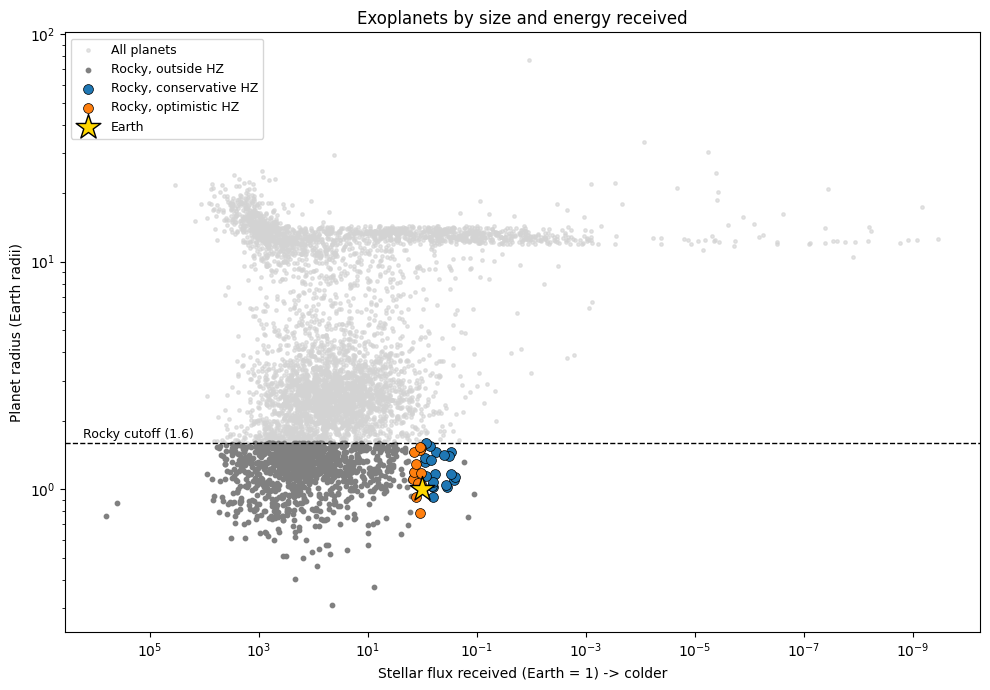

In [45]:
zone_colors = {"conservative": "tab:blue", "optimistic": "tab:orange"}
rocky_outside = rocky[rocky["hz_zone"] == "outside"]

fig, ax = plt.subplots(figsize=(10, 7))

ax.scatter(df_clean["flux_earth"], df_clean["pl_rade"],
           s=6, color="lightgray", alpha=0.6, label="All planets")
ax.scatter(rocky_outside["flux_earth"], rocky_outside["pl_rade"],
           s=10, color="gray", label="Rocky, outside HZ")

for zone, color in zone_colors.items():
    sub = candidates[candidates["hz_zone"] == zone]
    ax.scatter(sub["flux_earth"], sub["pl_rade"], s=50, color=color,
               edgecolor="black", linewidth=0.5, label=f"Rocky, {zone} HZ", zorder=3)

ax.scatter(1, 1, marker="*", s=350, color="gold", edgecolor="black",
           label="Earth", zorder=4)

ax.axhline(ROCKY_MAX_RADIUS, ls="--", color="black", lw=1)
ax.text(0.02, ROCKY_MAX_RADIUS * 1.05, f"Rocky cutoff ({ROCKY_MAX_RADIUS})",
        transform=ax.get_yaxis_transform(), fontsize=9)

ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("Stellar flux received (Earth = 1) -> colder")
ax.set_ylabel("Planet radius (Earth radii)")
ax.set_title("Exoplanets by size and energy received")
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
fig.savefig("size_vs_flux.png", dpi=200)
plt.show()

Notice that the vast majority of planets sit far to the left of Earth, receiving much more energy. This is partly a detection bias: planets close to their stars transit more often and are easier to find.

Some takeaways:
- Candidates cluster right around Earth, which is exactly what this pipeline should produce: Earth-sized planets receiving Earth-like energy.
- The strange horizontal cluster of dots at about 13 Earth radii is explained by the data set (i.e. it's not an actual phenomenom from astronomy). Those dots are giant planets found by radial velocity, microlensing, or direct imaging, which don’t measure size. The archive estimates their radius from their mass, and above roughly Saturn’s mass, the estimate flattens out to about Jupiter’s size. This is why hundreds of planets share nearly the same radius, and why that line stretches to absurdly low fluxes: directly imaged planets orbit hundreds of AU from their stars.
- There is a gap near the rocky cutoff, as the clump of rocky planets below it and the clump above it (around 2-3 Earth radii) have fewer planets in between. This is actually a real phenemonen astronomers call the radius valley, and it’s the reason 1.6 was a good pick for the cutoff.
- The top-left corner is nearly empty: very few giant planets sit at extremely high flux. This is also a known feature, the hot Neptune desert: planets that size that close to their stars likely get their atmospheres stripped away.

# 11. Visualization: The habitable zone vs. star temperature

Classic habitable-zone chart, uses the "hz_flux_limit" function from earlier to draw the boundaries across all star temperatures from 2,600 to 7,200 K. The darker green band is the conservative zone and the lighter band is the optimistic zone. For cooler stars (lower on the chart), the zone shifts toward lower flux, which is the effect explained earlier, since red starlight heats planets more efficiently.

Rocky planets and candidates are plotted on top, with Earth’s star marking the Sun. I also added a highlight list to label some well-known planets in the space world. The x-axis is limited to 20 down to 0.1 to zoom in on the interesting region, so rocky planets receiving more than 20 times Earth’s energy are off the chart (those are way too hot either way).

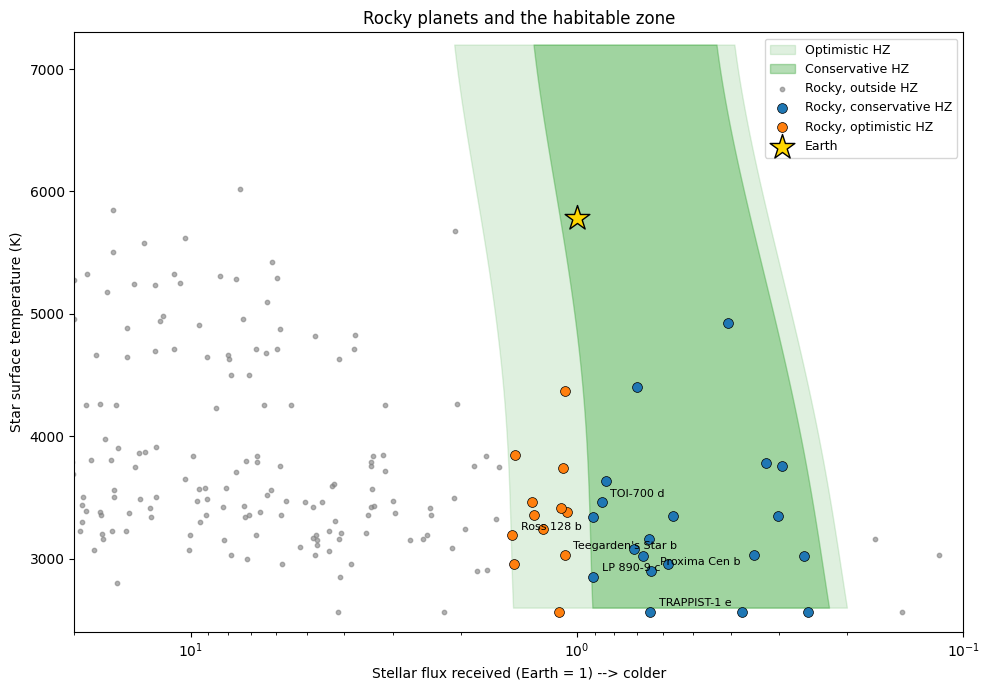

In [46]:
teff_grid = np.linspace(2600, 7200, 300)
lims = {name: hz_flux_limit(teff_grid, c) for name, c in HZ_COEFFS.items()}

fig, ax = plt.subplots(figsize=(10, 7))

ax.fill_betweenx(teff_grid, lims["early_mars"], lims["recent_venus"],
                 color="tab:green", alpha=0.15, label="Optimistic HZ")
ax.fill_betweenx(teff_grid, lims["maximum_greenhouse"], lims["runaway_greenhouse"],
                 color="tab:green", alpha=0.35, label="Conservative HZ")

ax.scatter(rocky_outside["flux_earth"], rocky_outside["st_teff"],
           s=10, color="gray", alpha=0.6, label="Rocky, outside HZ")
for zone, color in zone_colors.items():
    sub = candidates[candidates["hz_zone"] == zone]
    ax.scatter(sub["flux_earth"], sub["st_teff"], s=50, color=color,
               edgecolor="black", linewidth=0.5, label=f"Rocky, {zone} HZ", zorder=3)

ax.scatter(1, 5780, marker="*", s=350, color="gold", edgecolor="black",
           label="Earth", zorder=4)

# list of well-known planets I chose to highlight
highlight = ["Proxima Cen b", "TRAPPIST-1 e", "Teegarden's Star b",
             "TOI-700 d", "Ross 128 b", "LP 890-9 c"]
for _, row in candidates[candidates["pl_name"].isin(highlight)].iterrows():
    ax.annotate(row["pl_name"], (row["flux_earth"], row["st_teff"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)

ax.set_xscale("log")
ax.set_xlim(20, 0.1)
ax.set_ylim(2400, 7300)
ax.set_xlabel("Stellar flux received (Earth = 1) --> colder")
ax.set_ylabel("Star surface temperature (K)")
ax.set_title("Rocky planets and the habitable zone")
ax.legend(loc="upper right", fontsize=9)

plt.tight_layout()
fig.savefig("habitable_zone.png", dpi=200) # save as PNG
plt.show()

Some takeaways:
- The bands curve just as the physics predicts: the cooler the star, the lower the flux needed for the habitable zone.
- TRAPPIST-1’s planets sit just below the shaded region, at the model’s 2,600 K edge, exactly as flagged.
- Every orange (optimistic) candidate is on the hot side of the conservative zone. None fall in the narrow cold-side sliver between maximum greenhouse and Early Mars. That makes sense, since that sliver is very thin.
- Almost all candidates are below 4,000 K, which shows the red-dwarf pattern from earlier at a glance.

# 12. Prep features for clustering

After visualization, we move into the next phase of clustering with scikit-learn.

Here we pick three features that describe a planet's situation: its size, the energy it receives, and its star's temperature. Radius and flux are converted to log scale, for the same reason the charts use log axes: k-means groups points by distance, and on a normal scale a planet at 10,000 timesEarth's flux would make differences between 0.5 and 2 look meaningless.

StandardScaler is used to standardize every feature (mean 0, standard deviation 1) so that star temperature (values in the thousands) don't dominate the distance calculation, as the clustering would then basically just sort planets by star temperature.

In [47]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

features = pd.DataFrame({
    "log_radius": np.log10(df_clean["pl_rade"]),
    "log_flux":   np.log10(df_clean["flux_earth"]),
    "st_teff":    df_clean["st_teff"],
}, index=df_clean.index)

scaler = StandardScaler()
X = scaler.fit_transform(features)

print("Raw features:")
print(features.describe().round(2))
print()
print("After scaling, mean:", X.mean(axis=0).round(2), " std:", X.std(axis=0).round(2)) # confirm that scaling worked

Raw features:
       log_radius  log_flux   st_teff
count     5596.00   5596.00   5596.00
mean         0.57      1.56   5363.56
std          0.40      1.42   1251.34
min         -0.51     -9.47    575.00
25%          0.26      0.98   4910.00
50%          0.45      1.81   5555.00
75%          1.07      2.47   5905.73
max          1.89      5.80  40000.00

After scaling, mean: [-0. -0.  0.]  std: [1. 1. 1.]


# 13. Choose number of clusters

Now we run k-means nine times, with 2-10 clusters, and measures two things each time:

- Inertia: how far points are from the center of their cluster, in total. It always drops as you add clusters, so what we are looking for is the “elbow”: the point where adding more clusters stops helping much.
- Silhouette score: measures how well separated the clusters are, from -1 to 1. Higher is better, and a peak suggests a natural number of groups.

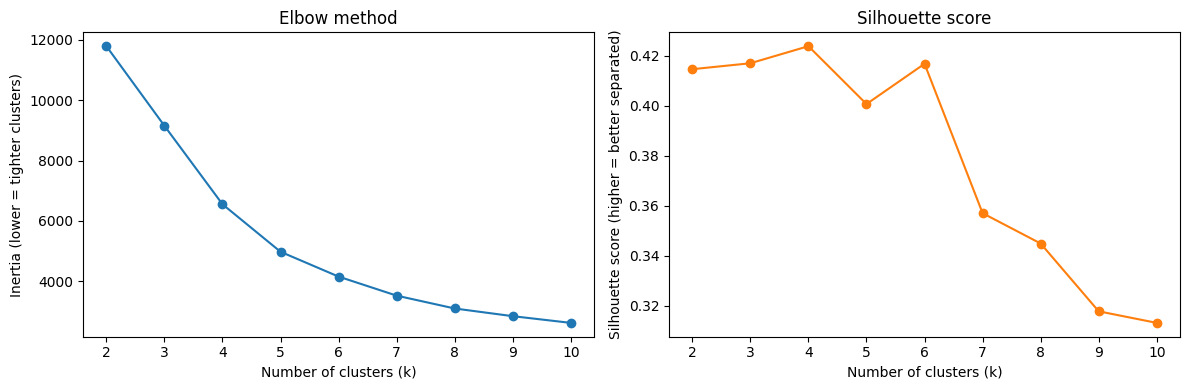

k=2: silhouette = 0.415
k=3: silhouette = 0.417
k=4: silhouette = 0.424
k=5: silhouette = 0.401
k=6: silhouette = 0.417
k=7: silhouette = 0.357
k=8: silhouette = 0.345
k=9: silhouette = 0.318
k=10: silhouette = 0.313


In [48]:
k_values = range(2, 11)
inertias, silhouettes = [], []

# use n_init=10 to run each version ten times from different random starting
# points and keeps the best, because k-means can get stuck in a poor solution.
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42) # reproducible
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(k_values, inertias, marker="o")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("Inertia (lower = tighter clusters)")
ax1.set_title("Elbow method")

ax2.plot(k_values, silhouettes, marker="o", color="tab:orange")
ax2.set_xlabel("Number of clusters (k)")
ax2.set_ylabel("Silhouette score (higher = better separated)")
ax2.set_title("Silhouette score")

plt.tight_layout()
fig.savefig("choosing_k.png", dpi=200)
plt.show()

for k, s in zip(k_values, silhouettes):
    print(f"k={k}: silhouette = {s:.3f}")

As seen above, the two methods mostly agree, and the choice is fairly clear:
- Silhouette peaks at k = 4 (0.424), with k = 6 a close second (0.417). After 6, it drops sharply, which means extra clusters just start cutting natural groups in half.\
- Elbow: inertia falls steeply from 2 to 4, then the curve bends and flattens after about 4-5. Each additional cluster after that buys less and less.

So k = 4 is the best-supported choice as it's the silhouette peak and sits right at the elbow.

# 14. Fit the final model and profile each cluster

Fit k-means with 4 clusters and save each planet's cluster number as a new column.

We also pass Earth through the same scalar as the other planets and see which cluster Earth would be assigned to if it were part of the data set.

The output table serves as a profile of the clusters (number of planets, typical size, etc.). I also used medians instead of means so that a few  planets on the extreme don't skew the results.

In [49]:
K = 4

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df_clean["cluster"] = kmeans.fit_predict(X)

# Which cluster would Earth go into?
earth = pd.DataFrame([[0.0, 0.0, 5780.0]], columns=features.columns)
earth_scaled = scaler.transform(earth)
earth_cluster = kmeans.predict(earth_scaled)[0]

df_clean["is_candidate"] = df_clean["is_rocky"] & (df_clean["hz_zone"] != "outside")

profile = df_clean.groupby("cluster").agg(
    planets=("pl_name", "size"),
    median_radius=("pl_rade", "median"),
    median_flux=("flux_earth", "median"),
    median_star_teff=("st_teff", "median"),
    pct_rocky=("is_rocky", "mean"),
    hz_candidates=("is_candidate", "sum"),
)
profile["pct_rocky"] = (profile["pct_rocky"] * 100).round(1)

print(f"Earth would belong to cluster {earth_cluster}")
display(profile.round(2))

Earth would belong to cluster 1


,planets,median_radius,median_flux,median_star_teff,pct_rocky,hz_candidates
cluster,,,,,,
0,1347,12.70,264.29,5710.0,0.0,0
1,3619,2.12,68.51,5494.0,30.3,32
2,623,12.80,0.16,5508.0,0.0,0
3,7,12.30,9.67,29300.0,28.6,0


So the clusters we got are:

0. Hot giants. Jupiter-sized planets receiving about 264 times Earth's energy, i.e. “hot Jupiters”.
1. Small planets. Rocky worlds and mini-Neptunes, median about 2 Earth radii. Earth and all 32 of our candidates are here.
2. Jupiter-sized planets far from their stars. This cluster contains most of that artificial 13 R⊕ line of estimated radii.
3. Planets around extremely hot stars (median 29,300 K, five times hotter than the Sun).

# 15. Visualizing the clusters

Now we'll redo the first chart with each planet colored by its cluster. The 32 candidates are outlined in black.


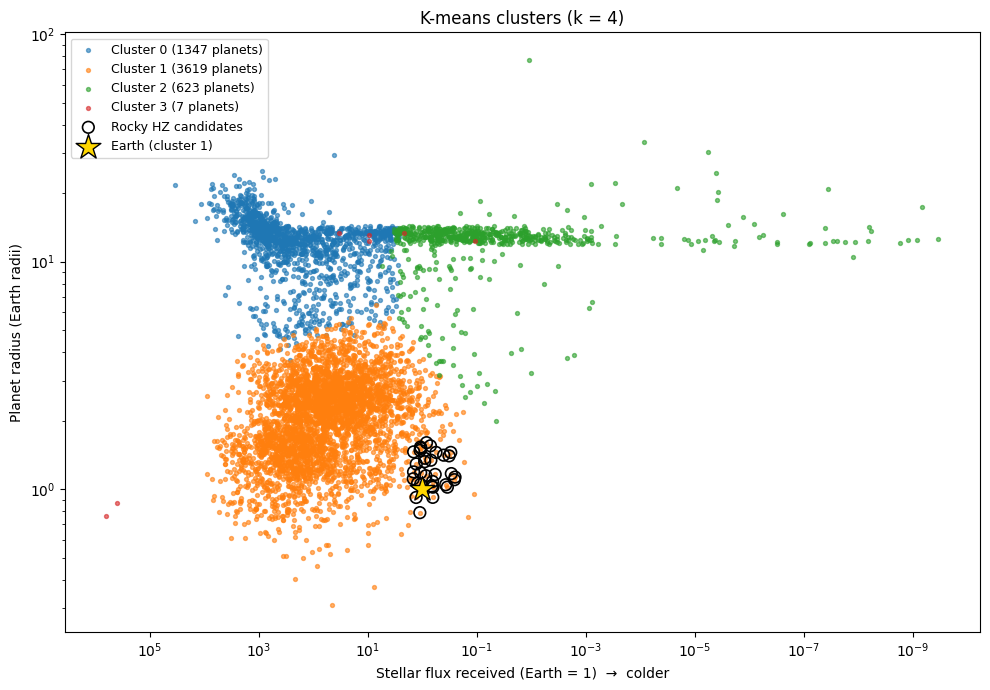

In [50]:
fig, ax = plt.subplots(figsize=(10, 7))

for c in range(K):
    sub = df_clean[df_clean["cluster"] == c]
    ax.scatter(sub["flux_earth"], sub["pl_rade"], s=8, alpha=0.6,
               color=plt.cm.tab10(c), label=f"Cluster {c} ({len(sub)} planets)")

cand = df_clean[df_clean["is_candidate"]]
ax.scatter(cand["flux_earth"], cand["pl_rade"], s=70, facecolors="none",
           edgecolors="black", linewidths=1.2, label="Rocky HZ candidates", zorder=3)

ax.scatter(1, 1, marker="*", s=350, color="gold", edgecolor="black",
           label=f"Earth (cluster {earth_cluster})", zorder=4)

ax.set_xscale("log")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("Stellar flux received (Earth = 1)  →  colder")
ax.set_ylabel("Planet radius (Earth radii)")
ax.set_title(f"K-means clusters (k = {K})")
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout()
fig.savefig("clusters.png", dpi=200)
plt.show()

Note: The clustering used three features, but the chart only shows two (no star temperature), so two planets that look close on this visual might be in different clusters because their stars differ.

# 16. Ranking planets by similarity to Earth

Taking clustering a step further: since every planet already has coordinates in the scaled feature space, we can measure its straight-line distance from Earth's point and rank planets by overall similarity. A distance of 0 is an exact match for Earth's size, energy received, and star type.

“near misses”: planets that look very Earth-like overall but failed one of the strict cutoffs, e.g. they are 1.65 Earth radii (just over the rocky line) or just outside the habitable zone. This list could be worth investigating further as these planets are borderline on one measure but excellent on the others.

In [51]:
df_clean["dist_to_earth"] = np.linalg.norm(X - earth_scaled, axis=1)

most_earthlike = df_clean.sort_values("dist_to_earth").head(20)
display(most_earthlike[[
    "pl_name", "pl_rade", "flux_earth", "st_teff", "cluster",
    "is_candidate", "hz_zone", "sy_dist", "dist_to_earth"
]].round(2))

near_misses = most_earthlike[~most_earthlike["is_candidate"]]
print(f"{len(near_misses)} of the 20 most Earth-like planets were NOT on the candidate list")

,pl_name,pl_rade,flux_earth,st_teff,cluster,is_candidate,hz_zone,sy_dist,dist_to_earth
5093,Kepler-1126 c,1.45,2.07,5678.0,1,False,outside,635.74,0.46
6294,Kepler-452 b,1.63,1.11,5757.0,1,False,optimistic,551.73,0.53
2370,Kepler-69 c,1.71,1.95,5638.0,1,False,outside,730.62,0.62
3346,Kepler-409 b,1.20,6.16,5421.0,1,False,outside,68.17,0.65
5828,Kepler-132 e,1.18,7.44,6023.0,1,False,outside,349.55,0.67
1638,Kepler-1638 b,1.87,1.39,5710.0,1,False,optimistic,1525.52,0.68
3846,Kepler-1126 b,1.73,4.68,5798.0,1,False,outside,635.74,0.75
4633,tau Cet h,1.19,8.38,5310.0,1,False,outside,3.60,0.77
1336,Kepler-176 e,1.45,5.99,5295.0,1,False,outside,527.32,0.78
957,Kepler-1185 b,1.33,10.36,5622.0,1,False,outside,459.27,0.79


19 of the 20 most Earth-like planets were NOT on the candidate list


# 17. Conclusion

The k-means used in this project essentially rediscovered the main planet types astronomers recognize, using only three numbers per planet and no labels (with Cluster 3 an outlier group - stars so unusual that the algorithm gave them their own cluster. They were among the 63 stars flagged as outside the habitable-zone model's range. After some reserach it appears that, in the plot from #15, the two small red dots at the far left are probably Kepler-70's planets, which were reported around a hot subdwarf star (and are disputed)).

With k = 4, the clustering can confirm that out candidates belong with the small planets, but it doesn't single them out: cluster 1 also contains thousands of really hot rocky planets and mini-Neptunes. The habitable zone is a tiny corner of the data, and broad clustering doesn't resolve that finely. Unsupervised clustering finds the big structure, and the physics-based filters we added find the needle in it. We could explore this more by seting k = 6 in the cell from #14 and rerunning cells #14-16 to see whether a separate temperate group appears.

The near misses are the most interesting part for me: the Earth-similarity ranking favors planets around Sun-like stars (because star temperature is one of the three features used), while our candidates mostly orbit red dwarfs, which is why 19 of the 20 weren't on our list. But let's look at the ones that are on the candidates list:
- Kepler-452 b (1.63 Earth radii) and Kepler-62 e (1.61 Earth radii) are both in the habitable zone and missed the rocky cutoff by only 0.03 and 0.01 Earth radii. Kepler-452 b orbits a near-twin of the Sun and was famously nicknamed “Earth's cousin" after its discovery in 2015.
- Kepler-22 b is in the conservative habitable zone of a Sun-like star, but at 2.1 Earth radii, it's probably a mini-Neptune, not rocky.
- tau Ceti f orbits one of the nearest Sun-like stars, only 3.6 parsecs away, and sits just past the cold edge of the habitable zone. Its radius is estimated, so it's uncertain.
- Kepler-62 f is the one planet that is both highly Earth-like and on our candidate list, around a K-type star a bit cooler than the Sun.

This shows exactly why near misses are worth investigating: hard cutoffs are useful, but the true radius cutoff isn't known to two decimal places. In fact, when raising the cutoff to 1.7 from 1.6 ("ROCKY_MAX_RADIUS = 1.7" in the code from #5), Kepler-452 b and Kepler-62 e join the list.

One honest limitation: the similarity distance weights all three features equally, so a planet receiving 6 times Earth's energy (like Kepler-409 b) can rank as “Earth-like” because its size and star match well, even though it’s far too hot for liquid water. Overall resemblance isn't the same as habitability.

In conclusion, out of 6,451 known exoplanets, 32 are rocky and receive the right amount of energy for liquid water. Nearly all orbit red dwarfs, and the closest (like Proxima Centauri b) are the best targets for future telescopes. Clustering shows these planets are part of the broad family of small worlds, and an Earth-similarity ranking surfaces near misses around Sun-like stars, such as Kepler-452 b, that strict cutoffs exclude.